# PathSnap: map matching and route reconstruction

Noisy GPS points from a vehicle are matched to the directed road arcs they were driven on, and the
matched arcs are joined into one connected route.

Pipeline: **raw files → candidate arcs per GPS point (20 features) → classifier scores each candidate
→ HMM/Viterbi picks a consistent sequence → shortest paths fill gaps → route**.

Everything here calls the code in `src/`. By default the notebook runs the fast path: it loads the
committed results and runs live inference. Set `RUN_FULL = True` to retrain all 6 models and re-run
the Optuna search (about 15 to 20 minutes).

In [1]:
RUN_FULL = False          # True = rebuild features, retrain 6 models, re-run Optuna (slow)
DEMO_TRIP = "00000007"    # student_test trip used for the live demo

import os, sys, time, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd, joblib
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
assert (ROOT / "src").exists(), "open this notebook from the codebase/ folder"
sys.path.insert(0, str(ROOT))
pd.set_option("display.precision", 4); pd.set_option("display.max_columns", 30)
RES, PLOTS, MAPS = ROOT/"artifacts/results", ROOT/"artifacts/plots", ROOT/"artifacts/maps"

def run(cmd):
    print(">", cmd); r = subprocess.run([sys.executable, *cmd.split()[1:]], cwd=ROOT, capture_output=True, text=True)  # same interpreter as the kernel
    print(r.stdout[-4000:], r.stderr[-2000:])

def show(*names, width=700):
    for n in names: display(Image(filename=str(PLOTS / n), width=width))

## 1. Dataset

Each trip folder has four whitespace-separated files:

| File | Content |
|---|---|
| `.track` | GPS points: lon, lat, unix time |
| `.nodes` | road graph nodes: lon, lat |
| `.arcs` | directed arcs: from node, to node |
| `.route` | ground truth: the arc ids driven, in order (never read at inference) |

There are 80 train trips and 10 student_test trips. Each trip has its own road network, and the
trips come from all over the world.

In [2]:
from src.data import DATA_ROOT, EXCLUDED_TRIPS, list_trips, load_trip, align_labels
for s in ["train", "student_test"]:
    print(f"{s:13s} {len(list_trips(s))} trips")
print("excluded from training:", sorted(EXCLUDED_TRIPS))

trip = load_trip("student_test", DEMO_TRIP)
print(f"\ntrip {DEMO_TRIP}: {len(trip.t)} GPS points, {len(trip.nodes_lonlat)} nodes, "
      f"{len(trip.arcs)} arcs, route of {len(trip.route)} arcs")

train         80 trips
student_test  10 trips
excluded from training: ['00000033', '00000054']

trip 00000007: 1354 GPS points, 2061 nodes, 4369 arcs, route of 123 arcs


### 1.1 Exploratory data analysis (all splits; `src/eda.py`)

In [3]:
if RUN_FULL: run("python -m src.eda")
display(pd.read_csv(RES/"eda_summary.csv"))
display(pd.read_csv(RES/"eda_inventory.csv").head(10))

,partition,n_trips,total_points,points_median,points_min,points_max,duration_s_median,nodes_median,arcs_median,route_len_median,extent_km_median,median_speed_mps_median,speed_min,speed_max,nan_or_invalid_coords,...,isolated_nodes_total,trips_route_noncontiguous,route_contig_frac_min,route_contig_frac_mean,label_dist_p50_median,label_dist_p90_median,labelled_frac_pooled,off50_frac_pooled,cand_points,cand_n_median,cand_n_p95,cand_fallback_frac,cand_miss_rate,cand_recall_25m,cand_recall_50m
0,train,80,208417,1529.0,361,19313,1710.0,9608.0,19526,280,9.5443,12.695,5.6714,41.371,0,...,0,10,0.9813,0.9993,4.6327,11.818,0.8888,0.1112,183152,6,16,0.0085,0.0011,0.9813,0.9989
1,train_clean,78,183260,1478.5,361,16031,1655.5,9608.0,19526,280,9.5443,12.813,5.6714,41.371,0,...,0,9,0.9813,0.9994,4.5986,11.786,0.9864,0.0136,183152,6,16,0.0085,0.0011,0.9813,0.9989
2,student_test,10,19160,1420.0,262,3958,1809.5,6596.5,13145,250,7.2433,15.015,8.5321,22.058,0,...,0,1,0.9973,0.9997,4.7478,12.511,0.9986,0.0014,19160,8,16,0.0000,0.0003,0.9866,0.9997


,split,trip_id,n_points,duration_s,n_nodes,n_arcs,route_len,size_track,size_nodes,size_arcs,size_route,n_nan_coords,n_invalid_coords,n_bad_ids,n_nonmono_t,n_gaps_10s,max_gap_s,median_speed_mps,extent_km,net_extent_km,n_components,largest_comp_frac,n_isolated_nodes,route_contig_frac,label_dist_p50,label_dist_p90,labelled_frac,off50_frac
0,train,1,1315,1357.0,88809,165790,525,40975,1687371,1948474,3119,0,0,0,0,1,16.0,41.3710,41.2710,43.7330,175,0.9780,0,1.0000,4.2950,10.218,1.0000,0.0000
1,train,2,7243,8933.2,7936,16139,262,238085,158720,156519,1398,0,0,0,0,41,160.0,7.0861,5.6191,8.2418,14,0.9766,0,0.9962,5.7654,131.550,0.8802,0.1198
2,train,3,821,823.0,9138,18028,79,26164,182760,175733,411,0,0,0,0,0,2.0,9.2971,4.4893,6.9852,42,0.9439,0,1.0000,4.4637,11.816,1.0000,0.0000
3,train,4,1064,5217.0,7350,15499,320,34982,147000,149738,1582,0,0,0,0,215,51.0,6.8565,16.3500,19.1400,12,0.9869,0,1.0000,8.5243,25.748,1.0000,0.0000
4,train,5,1045,1044.0,898,1579,105,33378,17960,12351,421,0,0,0,0,0,1.0,30.9070,28.7260,30.6170,3,0.9889,0,1.0000,4.5265,10.978,1.0000,0.0000
5,train,6,1450,2102.0,3259,6757,261,47576,65180,62914,1184,0,0,0,0,5,301.0,12.8650,6.9708,9.4850,8,0.9030,0,1.0000,4.5751,11.653,1.0000,0.0000
6,train,8,3093,3093.0,4995,10421,173,104055,104895,99150,832,0,0,0,0,0,2.0,7.6026,2.7713,5.6293,13,0.9836,0,1.0000,7.7725,21.887,0.9932,0.0068
7,train,10,2711,2710.0,8502,15715,210,88356,170040,153188,1042,0,0,0,0,0,1.0,8.3904,5.6707,8.1863,28,0.9340,0,1.0000,5.1890,13.270,1.0000,0.0000
8,train,11,2828,3735.0,2649,5393,565,92217,52980,49400,2167,0,0,0,0,1,909.0,18.9880,23.1400,24.6770,2,0.9970,0,1.0000,5.1104,12.348,1.0000,0.0000
9,train,12,1608,1608.0,16376,38599,205,51960,327520,410744,859,0,0,0,0,0,2.0,26.2590,32.4820,34.1780,22,0.9824,0,1.0000,5.1180,12.828,1.0000,0.0000


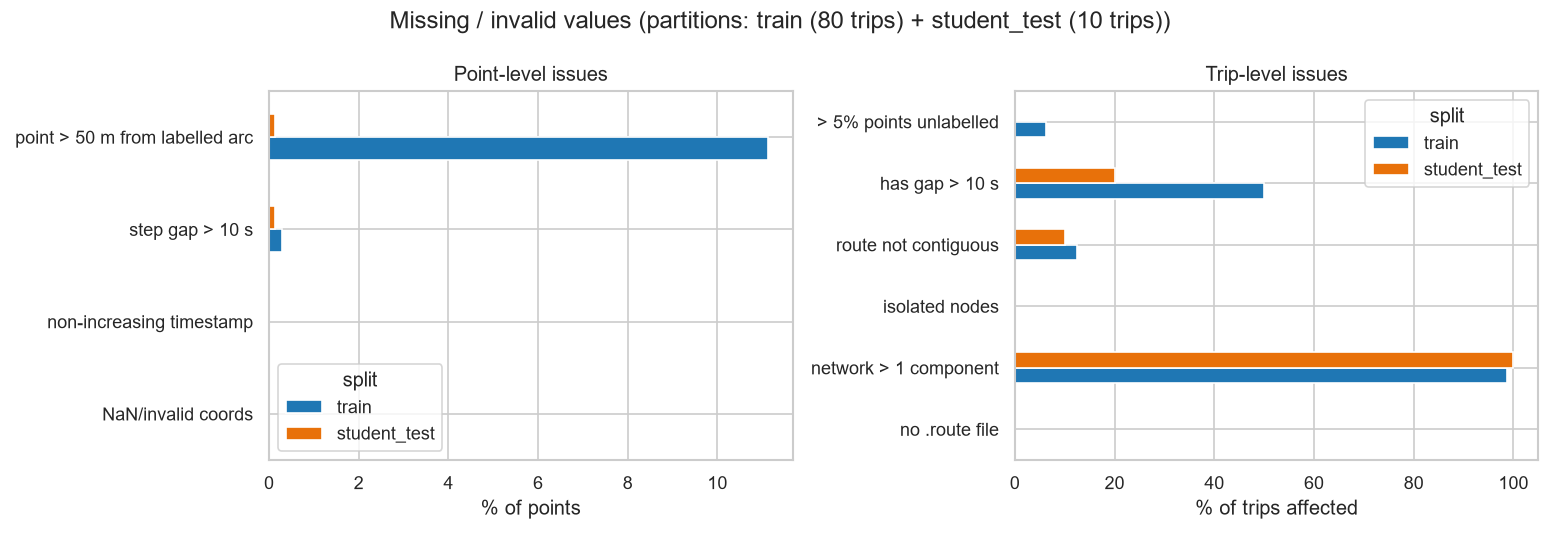

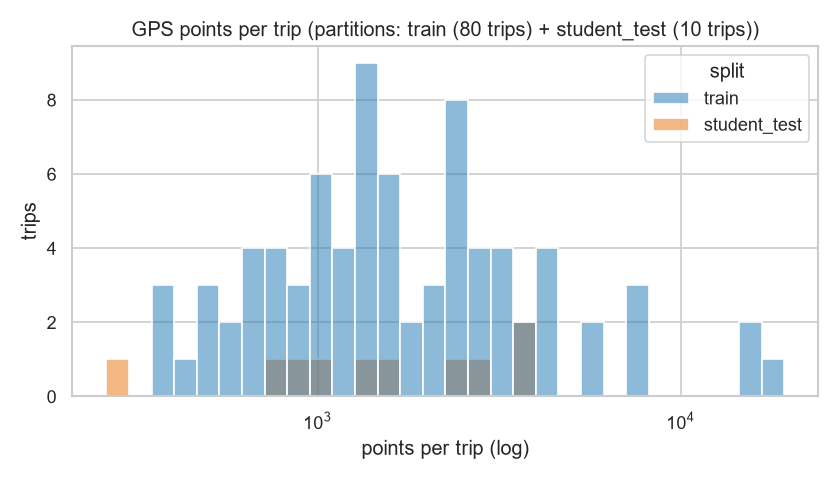

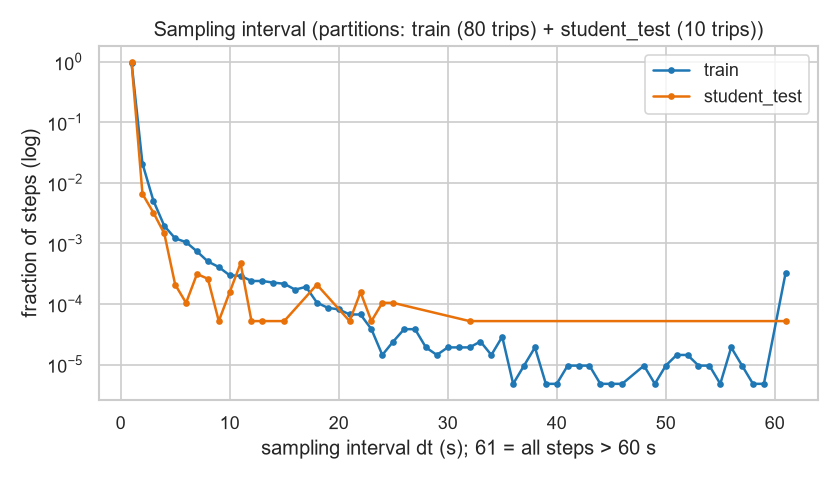

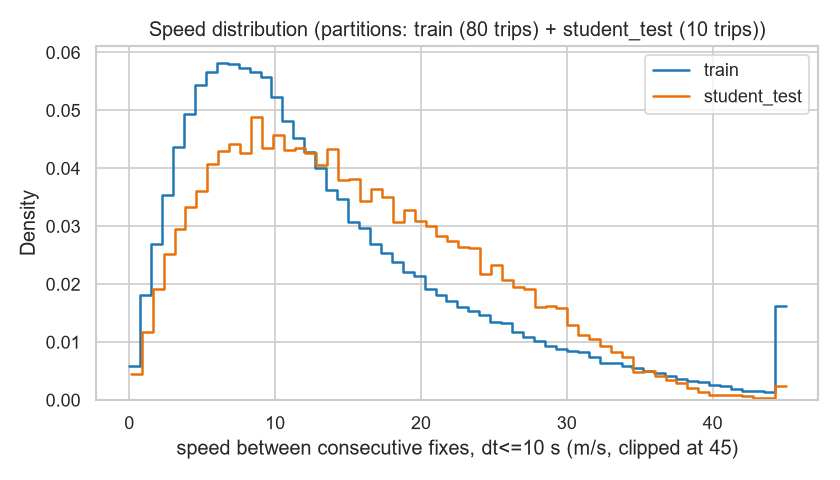

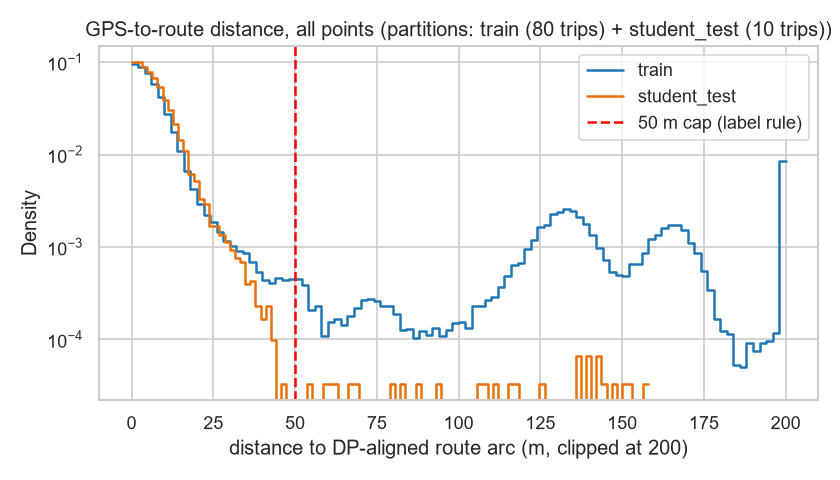

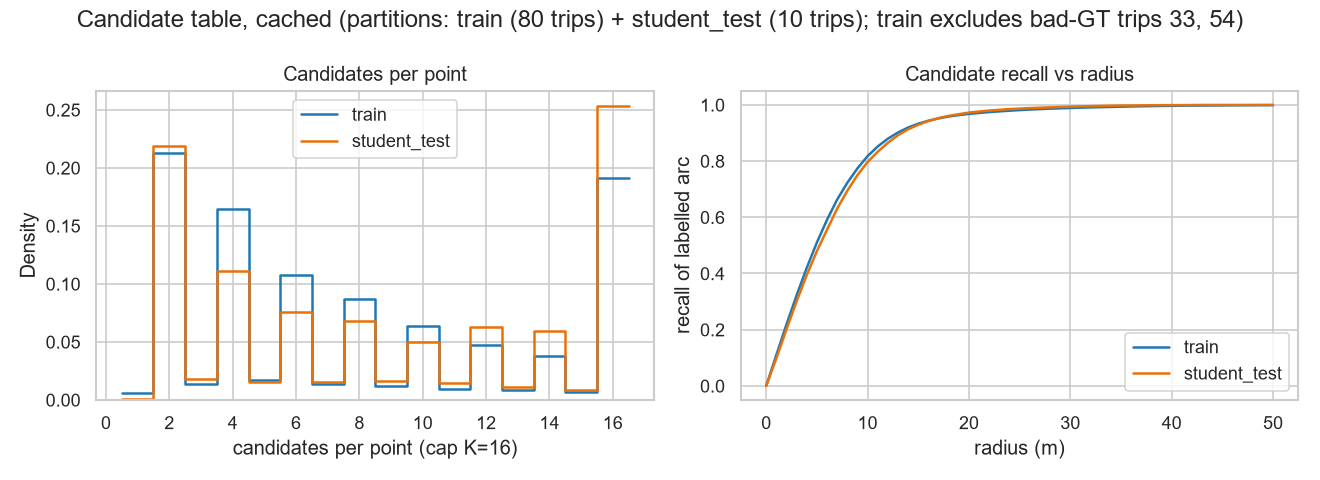

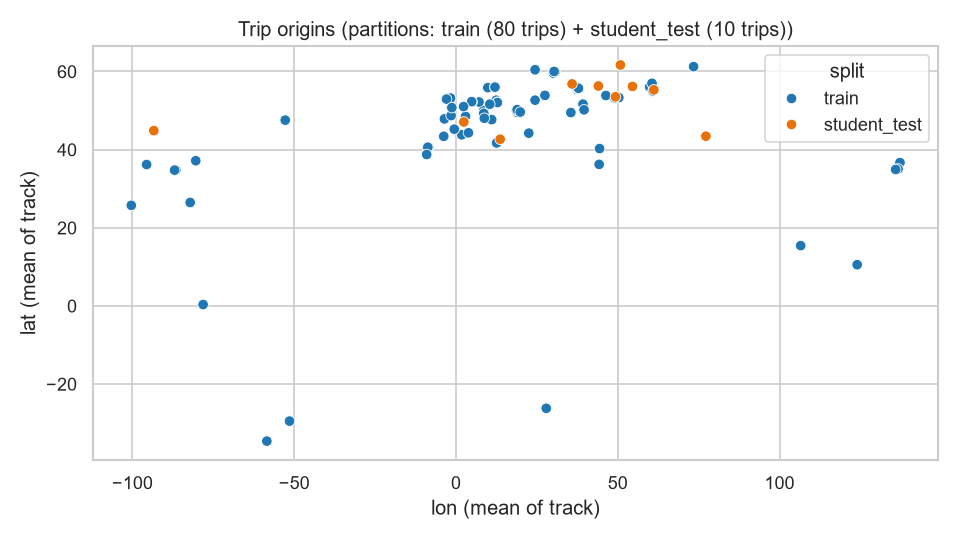

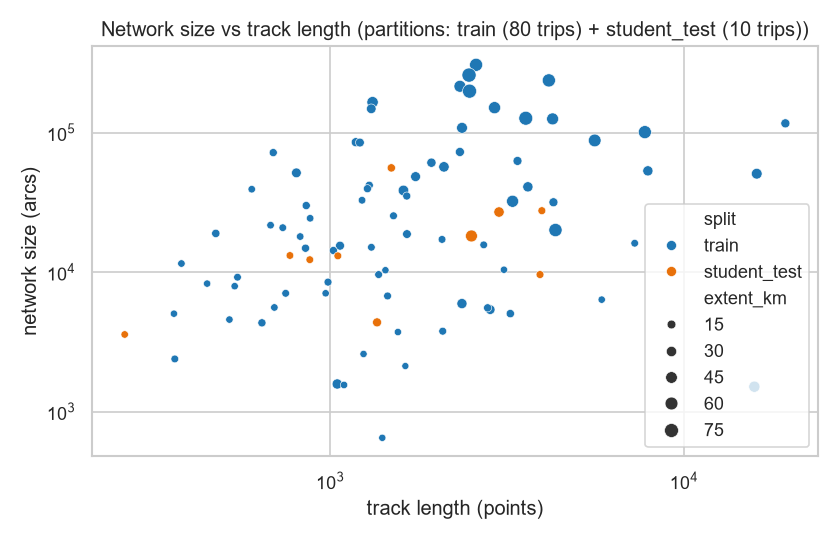

In [4]:
show("eda_missing_invalid.png", "eda_points_per_trip.png", "eda_sampling_interval.png", "eda_speed.png",
     "eda_gps_to_route_dist.png", "eda_candidates.png", "eda_origins.png", "eda_network_vs_track.png")

GPS trajectory against road network: a typical trip and one with bad ground truth (trip 33, excluded).

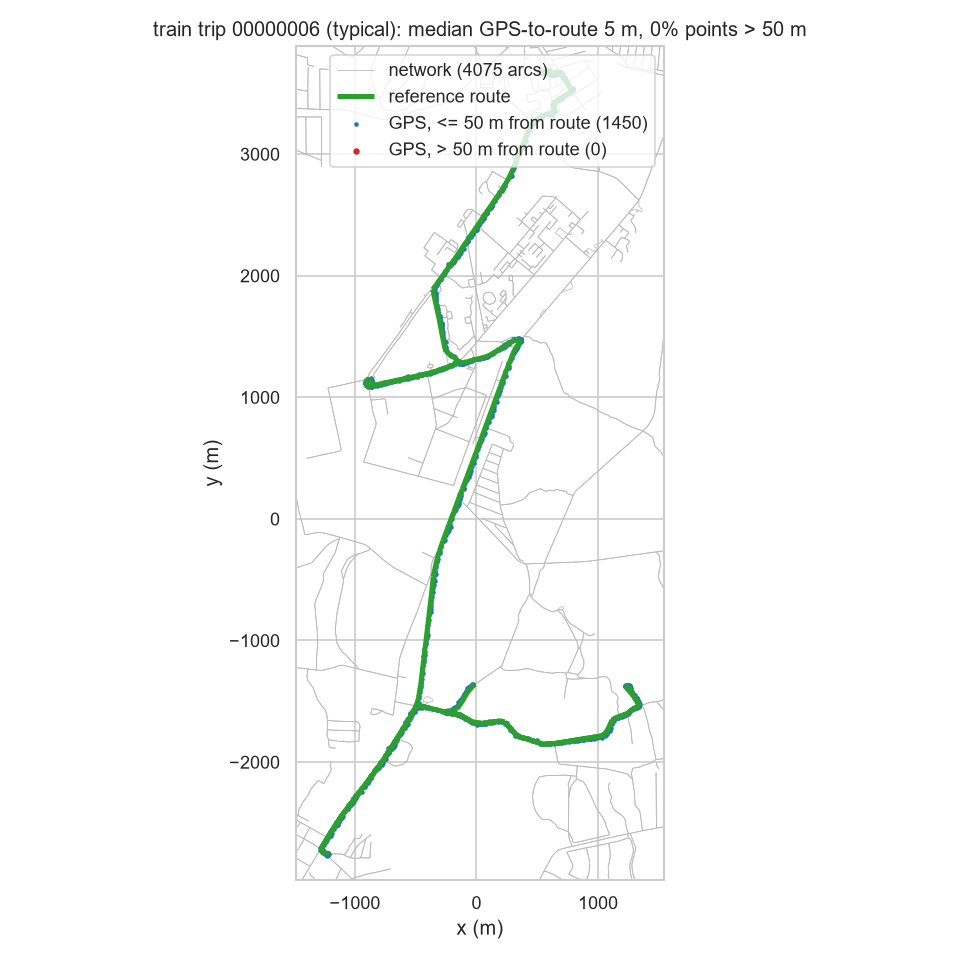

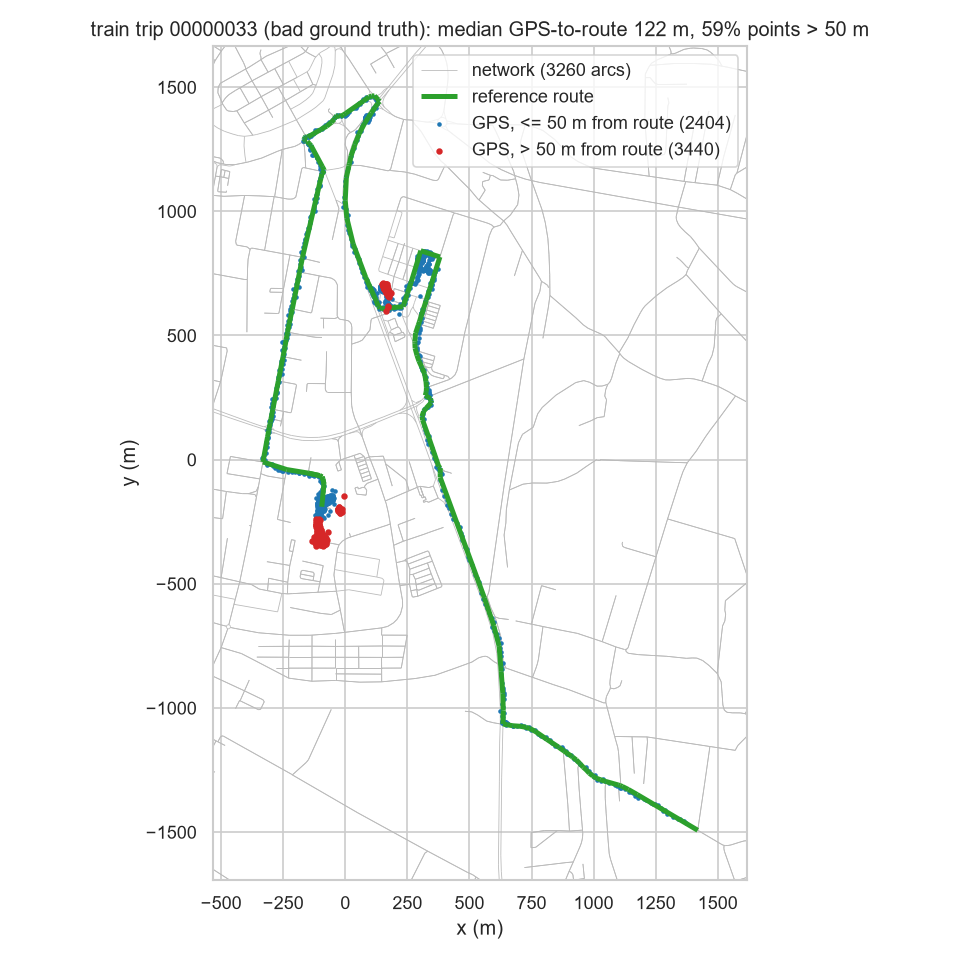

In [5]:
show("eda_traj_typical.png", "eda_traj_bad_gt.png")

### 1.2 Preprocessing and labels

* Coordinates are projected to local metres (equirectangular around the first point).
* Speed and heading come from consecutive points. Speed is 0 when dt ≤ 0 and capped at 70 m/s.
* Labels: each GPS point is aligned to the ground-truth route with a monotonic DP. The cost is
  distance plus a heading term, so on a U-turn the return leg gets the reverse arc. Points more than
  50 m from the route are left unlabelled.

In [6]:
lab, dist = align_labels(trip)
print(f"labelled points: {(lab >= 0).mean():.1%}   median GPS-to-route distance: {np.median(dist):.1f} m")

labelled points: 100.0%   median GPS-to-route distance: 4.5 m


## 2. Candidate generation and features (`src/features.py`)

For each GPS point we take every arc within **50 m** (at most 16). If none, we take the 4 nearest
arcs within 200 m (`fallback`). Each (point, candidate arc) pair is one row with 20 features, and the
target is 1 if that arc is the labelled one. This turns map matching into **binary classification**.

In [7]:
from src.features import FEATURES, load_dataset
if RUN_FULL:
    run("python -m src.features train"); run("python -m src.features student_test")
print(len(FEATURES), "features:", FEATURES)
st = load_dataset("student_test")
print(st.shape, "rows (candidates) on student_test,", st.groupby(["trip_id","pt_idx"]).ngroups, "points")
st.head(8)

20 features: ['dist', 'dist_rank', 'dist_gap', 'dist_ratio', 'proj_frac', 'edge_proj', 'arc_len', 'bearing_diff', 'cos_bearing', 'heading_ok', 'speed', 'dt_prev', 'dt_next', 'n_cand', 'has_twin', 'out_deg', 'in_deg', 'prev_link', 'next_link', 'fallback']
(169468, 25) rows (candidates) on student_test, 19160 points


,trip_id,pt_idx,arc_id,dist,dist_rank,dist_gap,dist_ratio,proj_frac,edge_proj,arc_len,bearing_diff,cos_bearing,heading_ok,speed,dt_prev,dt_next,n_cand,has_twin,out_deg,in_deg,prev_link,next_link,fallback,label,label_arc
0,00000000,0,17630,6.1089,0.0,0.0000,0.8593,0.8728,45.5475,358.0672,14.0668,0.9700,1.0,23.6211,1.0,1.0,6.0,1.0,3.0,3.0,0.0,1.0,0.0,1,17630
1,00000000,0,17634,6.1089,1.0,0.0000,0.8593,0.1272,45.5475,358.0672,165.9332,-0.9700,1.0,23.6211,1.0,1.0,6.0,1.0,3.0,3.0,0.0,1.0,0.0,0,17630
2,00000000,0,17635,27.6424,2.0,21.5335,3.8884,0.1399,36.7123,262.4819,149.4500,-0.8612,1.0,23.6211,1.0,1.0,6.0,1.0,3.0,3.0,0.0,1.0,0.0,0,17630
3,00000000,0,17668,27.6424,3.0,21.5335,3.8884,0.8601,36.7123,262.4819,30.5501,0.8612,1.0,23.6211,1.0,1.0,6.0,1.0,3.0,3.0,0.0,1.0,0.0,0,17630
4,00000000,0,212,45.9554,4.0,39.8465,6.4645,1.0000,0.0000,33.1605,165.8198,-0.9695,1.0,23.6211,1.0,1.0,6.0,1.0,3.0,2.0,0.0,1.0,0.0,0,17630
5,00000000,0,17633,45.9554,5.0,39.8465,6.4645,0.0000,0.0000,33.1605,14.1802,0.9695,1.0,23.6211,1.0,1.0,6.0,1.0,2.0,3.0,0.0,0.0,0.0,0,17630
6,00000000,1,17630,0.3677,0.0,0.0000,0.2689,0.9368,22.6348,358.0672,19.7938,0.9409,1.0,18.5347,1.0,1.0,6.0,1.0,3.0,3.0,1.0,1.0,0.0,1,17630
7,00000000,1,17634,0.3677,1.0,0.0000,0.2689,0.0632,22.6348,358.0672,160.2062,-0.9409,1.0,18.5347,1.0,1.0,6.0,1.0,3.0,3.0,1.0,1.0,0.0,0,17630


In [8]:
pts = st[st.label_arc >= 0].groupby(["trip_id","pt_idx"])
miss = 1 - pts.label.max().mean()
first = st.sort_values(["trip_id","pt_idx","dist"]).groupby(["trip_id","pt_idx"]).head(1)
first = first[first.label_arc >= 0]
print(f"true arc missing from candidates: {miss:.3%}")
print(f"baseline 'nearest arc':           {first.label.mean():.3f} Top-1")

true arc missing from candidates: 0.026%
baseline 'nearest arc':           0.537 Top-1


## 3. Six models, 5-fold GroupKFold by trip (`src/train.py`)

Folds group by trip, so no trip is in both train and validation. Metrics are taken per GPS point:
the candidate with the highest probability is the prediction.

* **Top-1**: share of points whose predicted arc is right (primary metric).
* **Macro F1**: over the binary candidate labels.
* **Log loss**: quality of the probabilities.

In [9]:
if RUN_FULL: run("python -m src.train")
ms = pd.read_csv(RES/"model_summary.csv").set_index("model")
rm = pd.read_csv(RES/"classifier_route_metrics.csv").set_index("model")
table = pd.DataFrame({
    "family": ms.family, "CV macro F1": ms.cv_macro_f1_mean, "CV Top-1": ms.cv_top1_mean,
    "Test Top-1": ms.st_top1, "Route continuity": rm.continuity, "Test macro F1": ms.st_macro_f1,
    "CV log loss": ms.cv_log_loss_mean, "Test log loss": ms.st_log_loss,
    "Train-fold Top-1": ms.cv_train_top1_mean, "Inference ms/trip": ms.infer_ms_per_trip})
table.sort_values("CV Top-1", ascending=False).round(3)

,family,CV macro F1,CV Top-1,Test Top-1,Route continuity,Test macro F1,CV log loss,Test log loss,Train-fold Top-1,Inference ms/trip
model,,,,,,,,,,
rf,bagging (trees),0.917,0.855,0.863,0.986,0.923,0.091,0.078,0.895,57.573
xgb,boosting (trees),0.917,0.855,0.861,0.986,0.922,0.093,0.080,0.916,9.973
lr,linear,0.916,0.853,0.856,0.988,0.919,0.195,0.183,0.865,8.029
lgbm,boosting (trees),0.914,0.850,0.860,0.984,0.921,0.104,0.090,0.906,49.382
mlp,neural network,0.910,0.843,0.853,0.986,0.917,0.115,0.087,0.888,5.317
nb,probabilistic,0.894,0.815,0.803,0.985,0.889,0.756,0.739,0.834,1.999


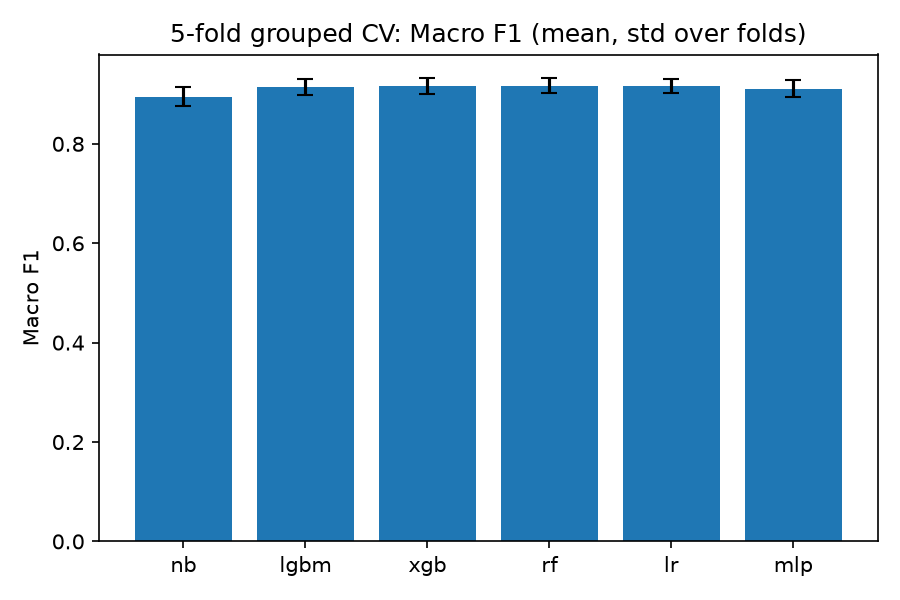

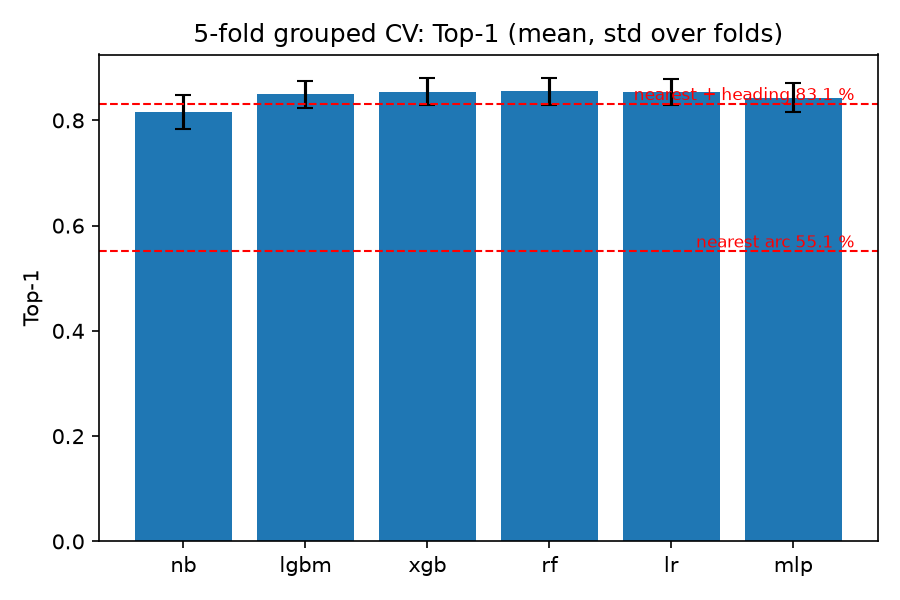

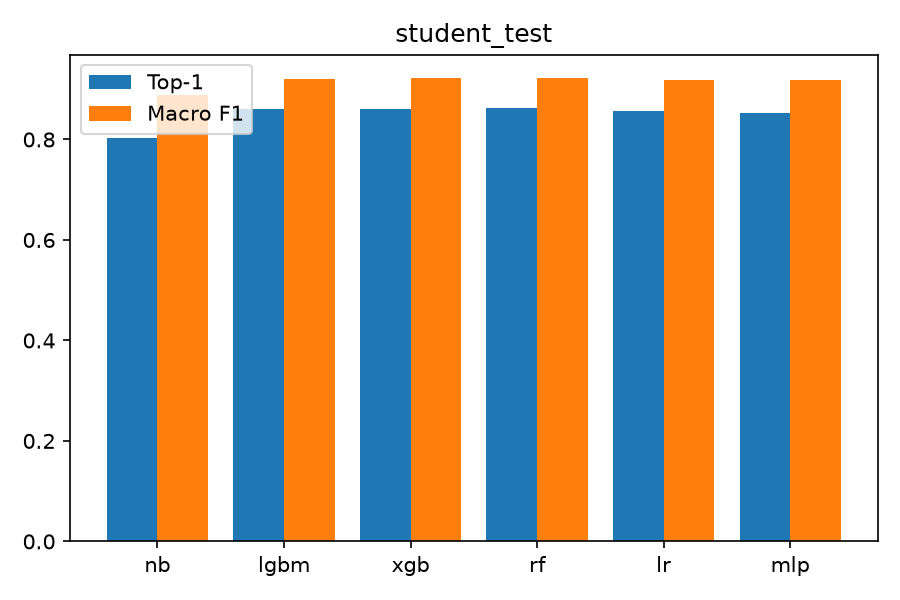

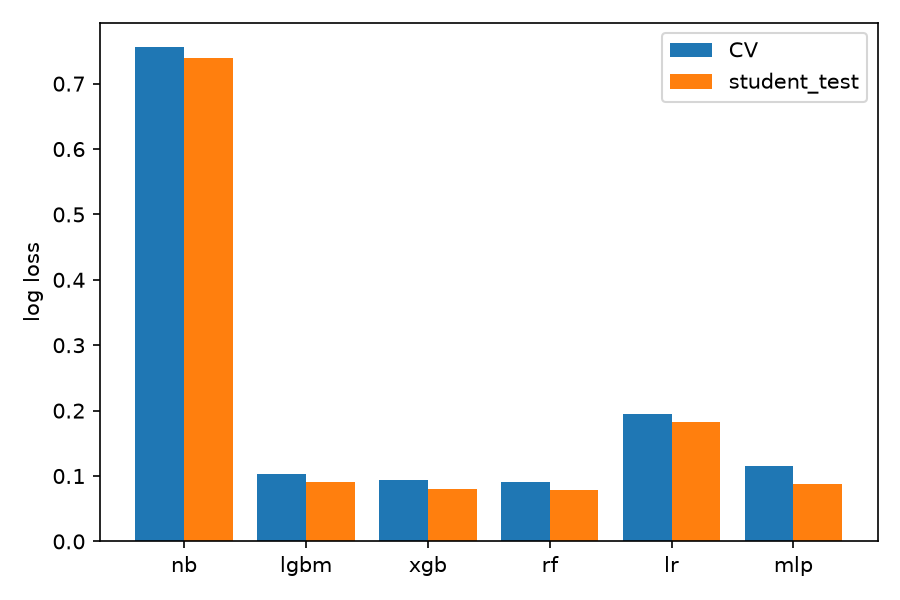

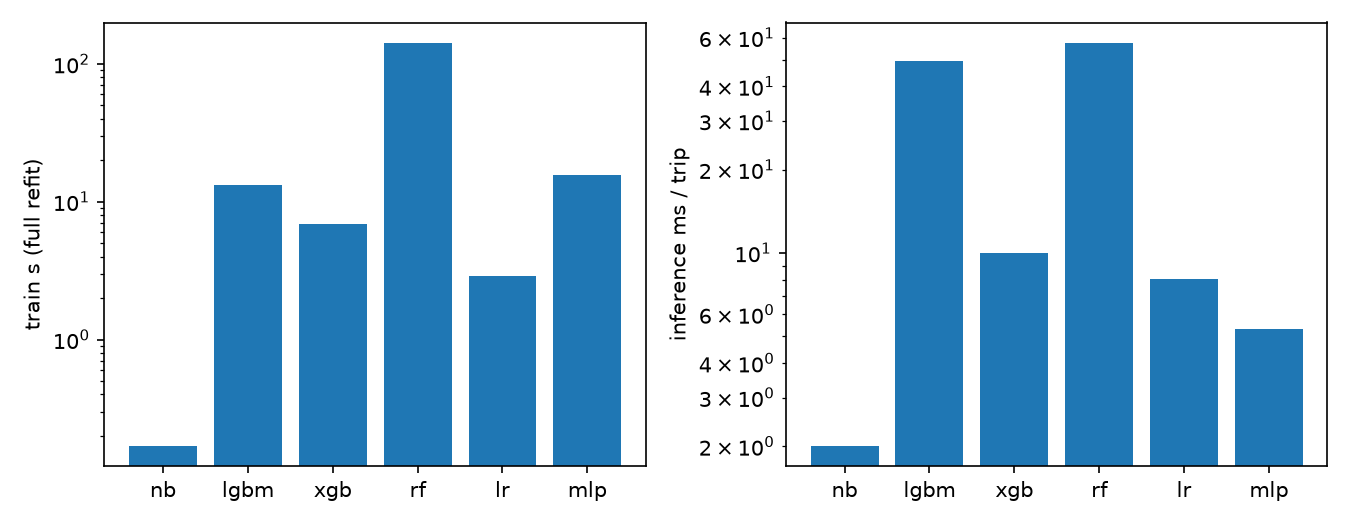

In [10]:
show("cv_macro_f1.png", "cv_top1.png", "student_test_top1_f1.png", "log_loss.png", "timing.png")

MLP is the only model with an epoch-wise training history:

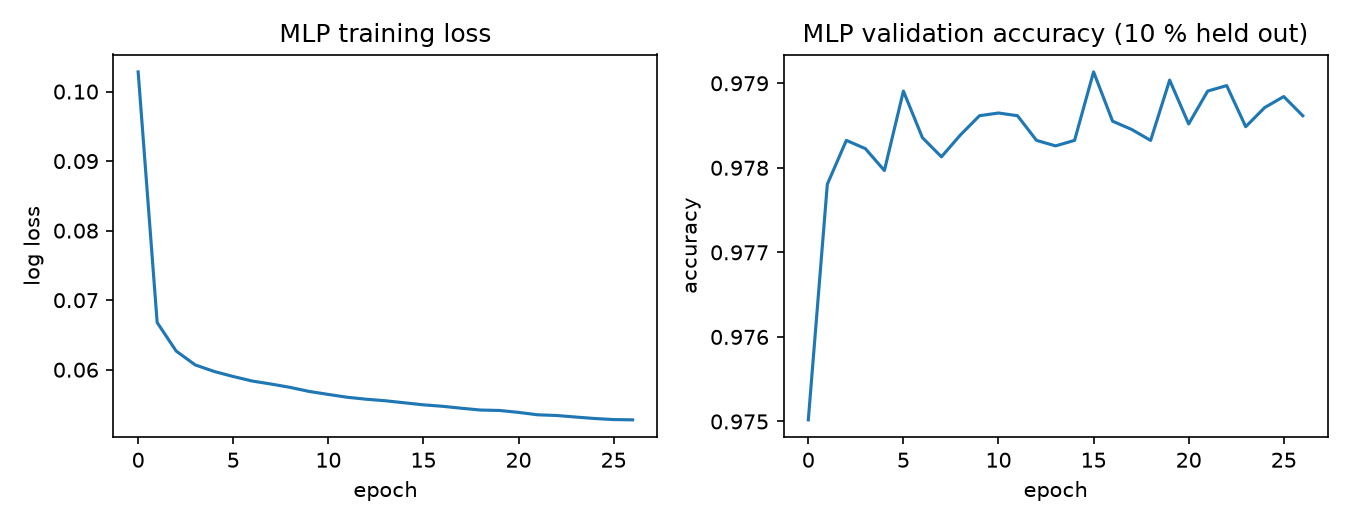

In [11]:
show("mlp_loss_curve.png", width=550)

Confusion matrices on student_test (candidate level):

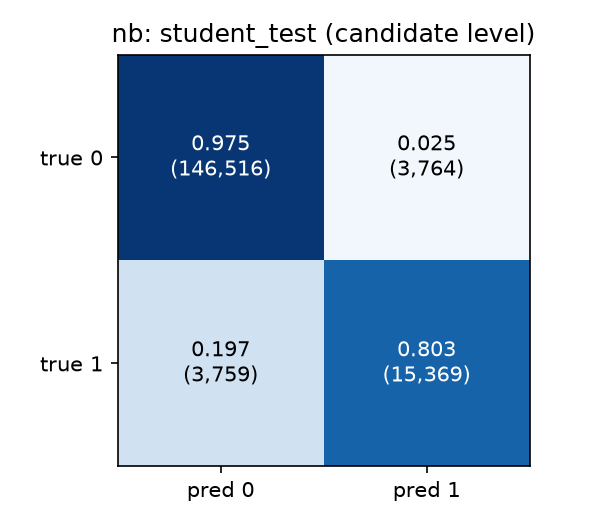

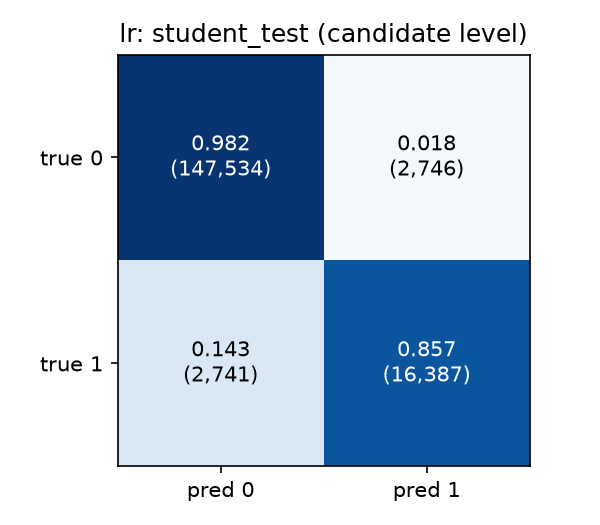

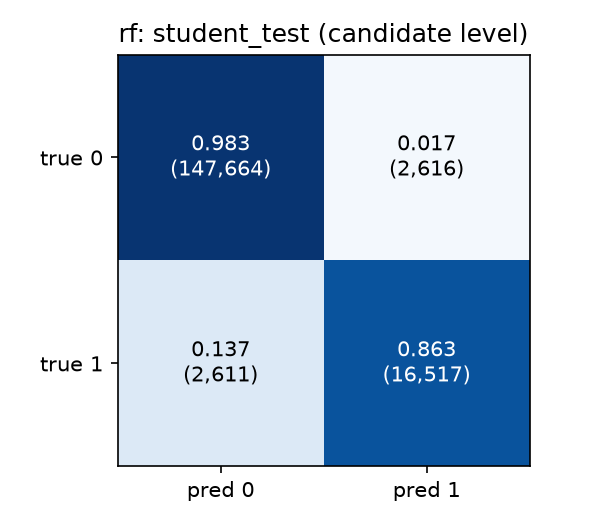

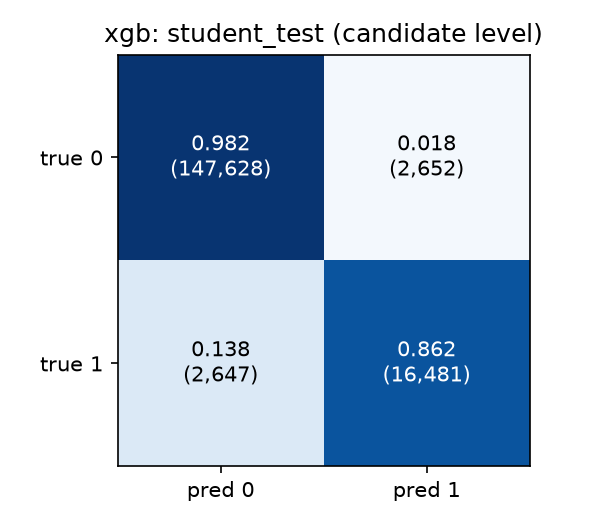

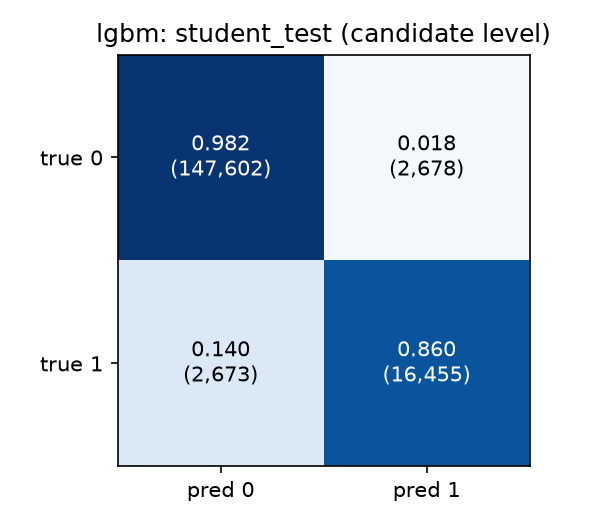

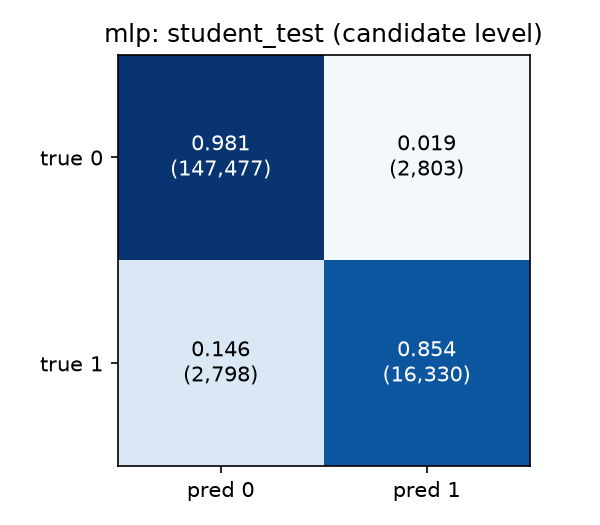

In [12]:
show(*[f"confusion_{m}.png" for m in ["nb","lr","rf","xgb","lgbm","mlp"]], width=420)

In [13]:
display(pd.read_csv(RES/'cv_results.csv').head(12))

,model,fold,top1,macro_f1,log_loss,miss_rate,n_points,precision,recall,train_top1,train_log_loss,train_s,infer_ms_per_1k,n_train_rows
0,nb,0,0.7951,0.8863,0.7140,2.9626e-03,29029,0.7951,0.7974,0.8105,0.8344,0.1831,0.1192,1152892
1,nb,1,0.7731,0.8671,0.9612,1.7334e-03,54807,0.7731,0.7744,0.8582,0.5759,0.1903,0.1368,1062869
2,nb,2,0.8311,0.9020,0.8408,8.6249e-05,34783,0.8311,0.8312,0.8427,0.6372,0.1727,0.1135,1179181
3,nb,3,0.8209,0.8984,0.7000,6.7295e-05,29720,0.8209,0.8210,0.8174,0.8971,0.1634,0.1063,1179911
4,nb,4,0.8559,0.9187,0.5627,1.5421e-04,32423,0.8559,0.8561,0.8406,0.6751,0.1515,0.1139,1147943
5,lgbm,0,0.8336,0.9078,0.0986,2.9626e-03,29029,0.8336,0.8361,0.8894,0.0788,10.8503,2.9394,1152892
6,lgbm,1,0.8140,0.8912,0.1331,1.7334e-03,54807,0.8140,0.8155,0.9276,0.0488,10.3004,3.1199,1062869
7,lgbm,2,0.8548,0.9158,0.1116,8.6249e-05,34783,0.8548,0.8549,0.9037,0.0651,10.5148,2.4159,1179181
8,lgbm,3,0.8697,0.9261,0.0954,6.7295e-05,29720,0.8697,0.8698,0.8899,0.0850,11.3260,2.8808,1179911
9,lgbm,4,0.8764,0.9303,0.0799,1.5421e-04,32423,0.8764,0.8766,0.9194,0.0516,10.7404,3.0318,1147943


## 4. Bayesian optimisation of XGBoost (`src/hpo.py`)

Optuna TPE sampler with a MedianPruner. The objective is mean grouped-CV Top-1, and student_test is
never used. We ran 15 trials over 8 hyperparameters.

In [14]:
if RUN_FULL: run("python -m src.hpo --model xgb --trials 15")
display(pd.read_csv(ROOT/"artifacts/hpo/hpo_summary.csv"))
display(pd.read_csv(ROOT/"artifacts/hpo/trials.csv").sort_values("value", ascending=False).head(8))
display(pd.read_csv(RES/"hpo_comparison.csv").round(4))

,model,trials,complete,pruned,wall_s,s_per_trial,best_n_estimators,best_learning_rate,best_subsample,best_colsample_bytree,best_reg_lambda,best_reg_alpha,best_max_depth,best_min_child_weight
0,xgb,15,11,4,710.8726,47.3915,333,0.0492,0.5369,0.7553,0.0087,1.9787,6,7.524


,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_log_loss,user_attrs_macro_f1,system_attrs_tpe:relative_params:0,state
13,13,0.8569,2026-11-18 12:17:29.863390,2026-11-18 12:17:59.929968,0 days 00:00:30.066578,0.7553,0.0492,6,7.5240,333,1.9787,0.0087,0.5369,0.0908,0.9183,"{""colsample_bytree"": 0.755267366734532, ""learn...",COMPLETE
7,7,0.8568,2026-11-18 12:12:47.787867,2026-11-18 12:13:30.918932,0 days 00:00:43.131065,0.6627,0.0195,9,2.9117,315,0.0122,0.0359,0.5226,0.0902,0.9183,NaN,COMPLETE
5,5,0.8568,2026-11-18 12:11:00.609887,2026-11-18 12:11:30.892001,0 days 00:00:30.282114,0.9547,0.0539,5,4.7492,358,0.4468,0.0108,0.5172,0.0911,0.9182,NaN,COMPLETE
2,2,0.8567,2026-11-18 12:08:17.804798,2026-11-18 12:09:05.971828,0 days 00:00:48.167030,0.6456,0.0596,5,2.9967,595,0.0036,0.2802,0.7160,0.0913,0.9182,NaN,COMPLETE
12,12,0.8565,2026-11-18 12:16:35.567736,2026-11-18 12:17:29.858196,0 days 00:00:54.290460,0.5359,0.0417,10,3.2265,410,0.1081,0.0067,0.5216,0.0920,0.9181,"{""colsample_bytree"": 0.5358833577850509, ""lear...",COMPLETE
10,10,0.8563,2026-11-18 12:14:40.944645,2026-11-18 12:16:18.865075,0 days 00:01:37.920430,0.5588,0.0234,10,15.0021,799,0.0215,0.0102,0.5022,0.0916,0.9180,"{""colsample_bytree"": 0.558804456190875, ""learn...",COMPLETE
6,6,0.8560,2026-11-18 12:11:30.896378,2026-11-18 12:12:47.783609,0 days 00:01:16.887231,0.8876,0.0188,7,15.8265,911,3.7959,5.7279,0.9848,0.0911,0.9178,NaN,COMPLETE
1,1,0.8559,2026-11-18 12:07:03.346537,2026-11-18 12:08:17.798848,0 days 00:01:14.452311,0.9850,0.1111,4,1.7323,982,0.0071,2.1368,0.5103,0.0931,0.9178,NaN,COMPLETE


,model_family,model,cv_top1,cv_macro_f1,cv_log_loss,st_top1,st_macro_f1,st_log_loss,infer_ms_per_trip,train_s
0,xgb,untuned,0.8547,0.9171,0.0935,0.8614,0.9219,0.0799,9.9727,6.8579
1,xgb,tuned,0.8569,0.9183,0.0908,0.8642,0.9235,0.0780,8.8414,6.9241


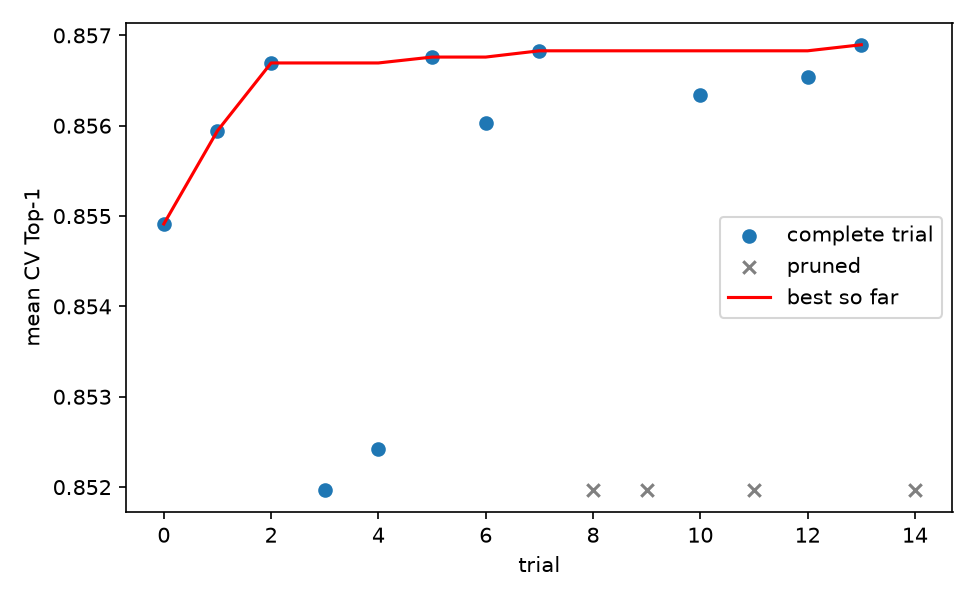

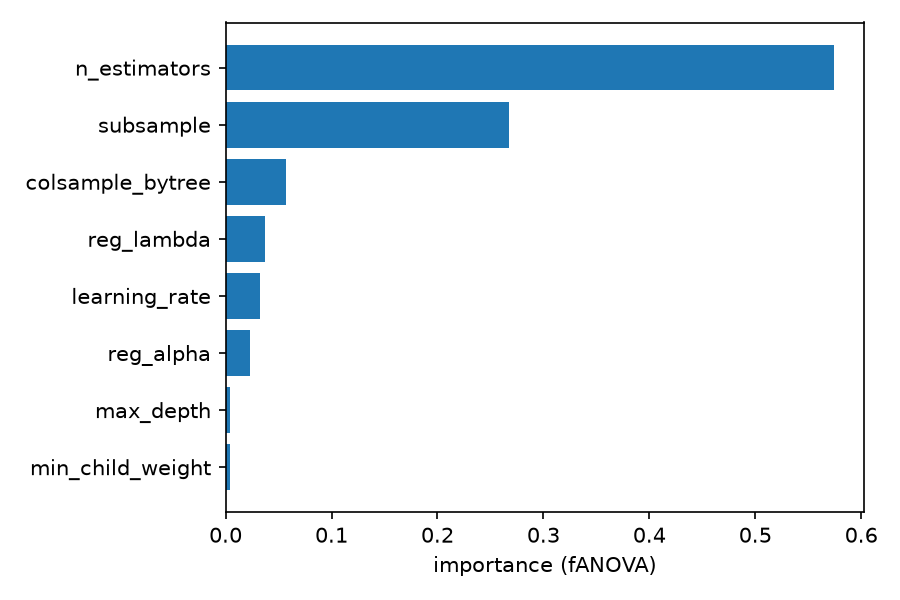

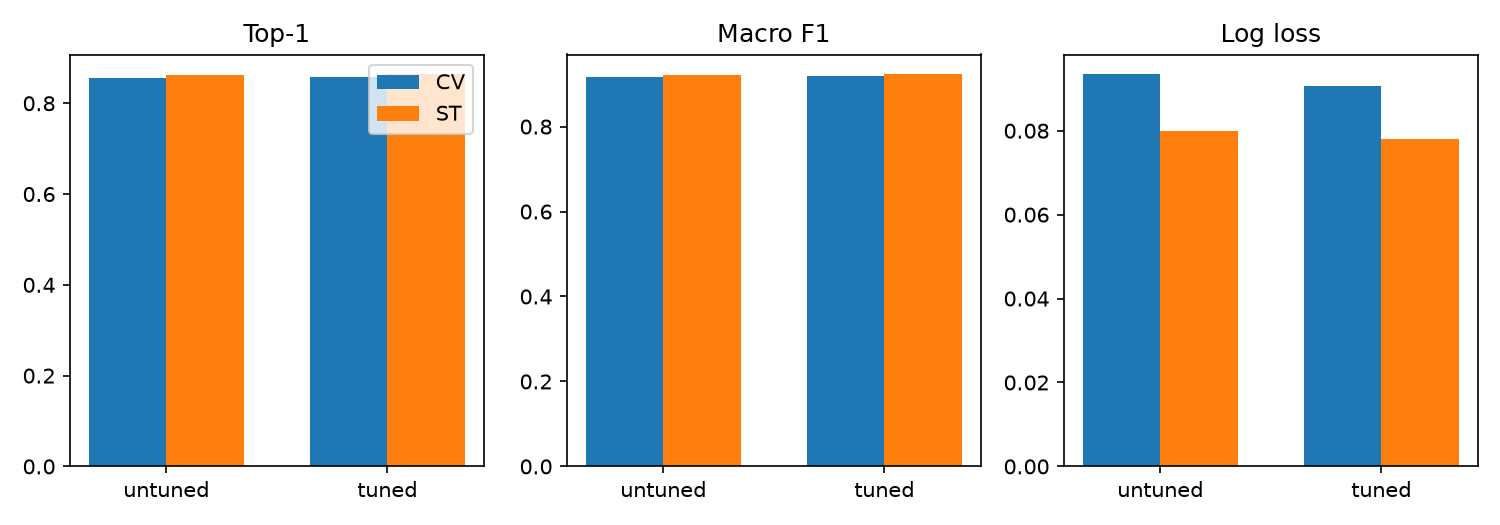

In [15]:
show("hpo_history.png", "hpo_param_importance.png", "hpo_tuned_vs_untuned.png")

### 4.1 Live check: reload the final model and re-score student_test

In [16]:
from src.train import predict_proba
from src.metrics import point_metrics
bundle = joblib.load(ROOT/"artifacts/models/final.joblib")
print("final model:", bundle["name"])
t0 = time.perf_counter(); p = predict_proba(bundle, st); dt = time.perf_counter() - t0
print(f"scored {len(st):,} candidates in {dt:.2f} s")
pd.Series(point_metrics(st, p)).round(4)

final model: xgb
scored 169,468 candidates in 0.18 s


top1             0.8642
macro_f1         0.9235
log_loss         0.0780
miss_rate        0.0003
n_points     19133.0000
precision        0.8642
recall           0.8644
dtype: float64

## 5. HMM and Viterbi route reconstruction (`src/hmm.py`, `src/predict.py`)

* **Hidden states**: the candidate arcs of each GPS point.
* **Emission**: `λ·log p(classifier) + (1−λ)·(−½(d/σ)²)`, with σ = 6.7 m and λ = 1.
* **Transition**: `−|road distance − straight-line distance| / β`, with β = 5. Road distance comes
  from Dijkstra on the trip graph, and U-turns get a penalty.
* **Gaps**: β grows with dt when dt > 10 s. The chain is broken when dt > 120 s or no transition is
  reachable.
* **Route**: Viterbi arcs are de-duplicated, and consecutive arcs are joined by shortest paths.

In [17]:
from src.predict import predict_trip
from src.hmm import route_metrics
rows, routes = [], {}
for name, b, hmm in [("classifier only", bundle, False), ("classifier + HMM", bundle, True),
                     ("Gaussian HMM (no ML)", None, True)]:
    r = predict_trip("student_test", DEMO_TRIP, b, use_hmm=hmm)
    routes[name] = r["route"]
    rows.append({"decoder": name, **route_metrics(trip, r["route"], trip.route),
                 "ms": r["timing_ms"]["total"]})
pd.DataFrame(rows).set_index("decoder").round(3)

,route_precision,route_recall,route_f1,continuity,n_breaks,ms
decoder,,,,,,
classifier only,0.962,0.993,0.977,1.0,0,55.131
classifier + HMM,0.992,0.993,0.993,1.0,0,414.023
Gaussian HMM (no ML),0.992,0.993,0.993,1.0,0,382.072


Over all 10 student_test trips (`python -m src.evaluate --split student_test`):

,split,mode,top1,route_precision,route_recall,route_f1,continuity,n_breaks,ms_total
0,student_test,classifier,0.883,0.747,0.997,0.847,0.986,23.8,40.403
1,student_test,hmm,0.949,0.975,0.996,0.985,1.000,0.1,732.561
2,student_test,gauss_hmm,0.943,0.975,0.995,0.985,1.000,0.1,611.535


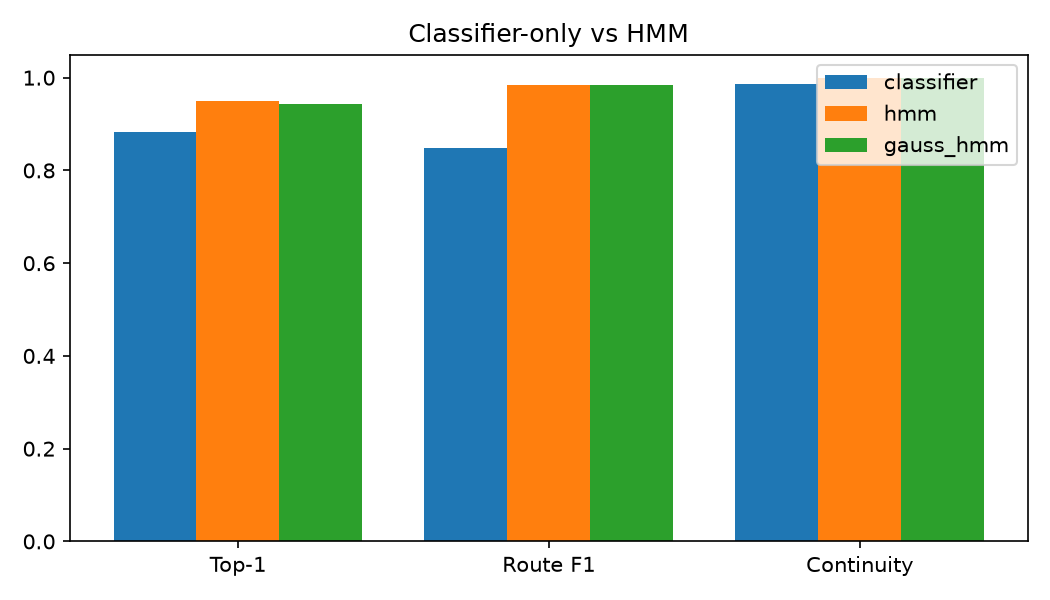

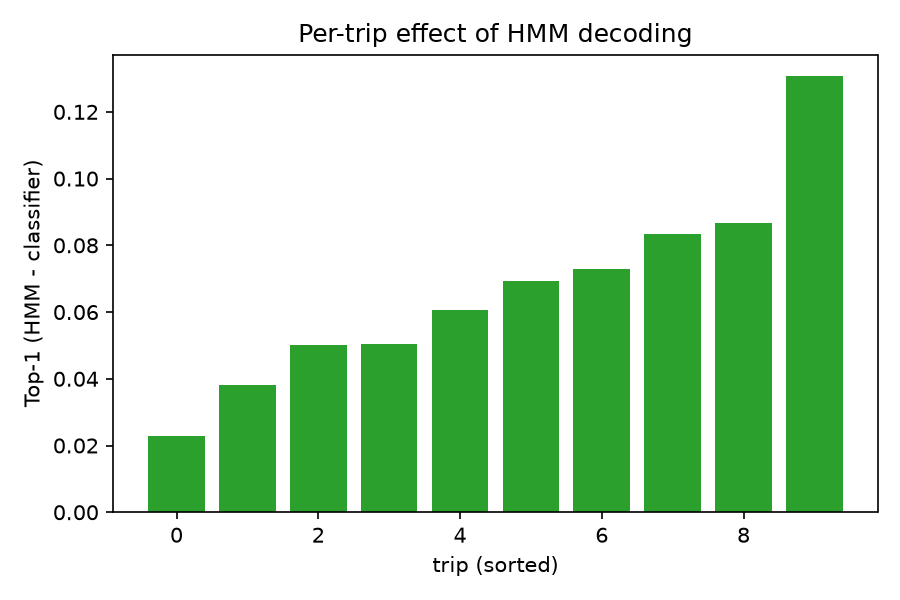

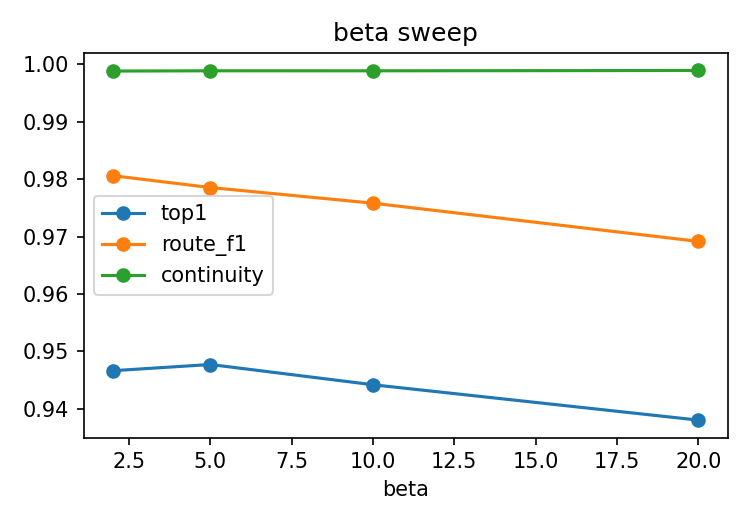

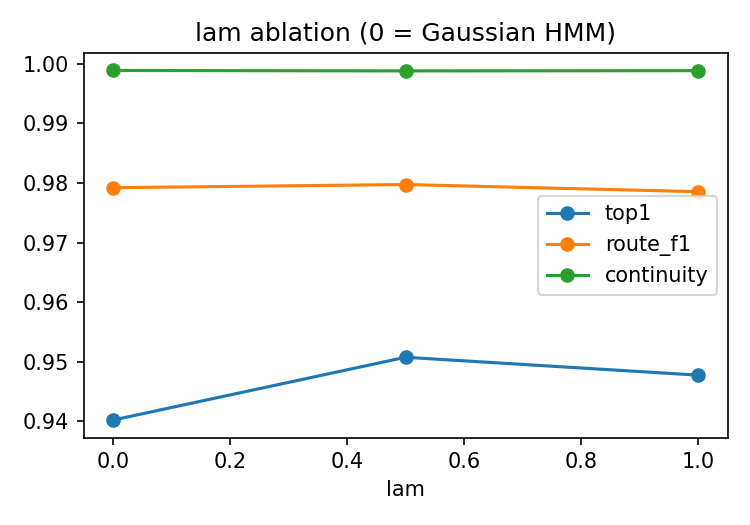

In [18]:
if RUN_FULL: run("python -m src.evaluate --split student_test")
display(pd.read_csv(RES/"hmm_summary.csv").round(3))
show("hmm_vs_classifier.png", "hmm_per_trip_delta.png", "hmm_beta.png", "hmm_lam.png")

## 6. Folium map (`src/maps.py`)

The layers are road network (grey), GPS points (blue), reference route (green), classifier-only
route (dashed) and HMM route. Use the layer control at the top right to toggle them.

In [19]:
from src.maps import trip_map
m = trip_map(trip, pred_route=routes["classifier + HMM"], ref_route=trip.route,
             other_routes={"classifier only": routes["classifier only"]})
m

## 7. API and UI (`api/server.py`, `ui/index.html`)

Laptop 1 runs the model API, and Laptop 2 serves the static UI, which calls it over the network.

```
# Laptop 1
set PATHSNAP_SPLIT=evaluator_test
uvicorn api.server:app --host 0.0.0.0 --port 8000
# Laptop 2
python -m http.server 5500 --directory ui     # open http://localhost:5500/?api=http://<LAPTOP1_IP>:8000
```

Endpoints: `GET /health`, `GET /trips`, `POST /predict {"trip_id": ...}`, `GET /map/{trip_id}`.
The call below runs the same handler in-process.

In [20]:
os.environ.setdefault("PATHSNAP_SPLIT", "student_test")
try:
    from fastapi.testclient import TestClient
    from api.server import app
    c = TestClient(app)
    print(c.get("/health").json())
    r = c.post("/predict", json={"trip_id": DEMO_TRIP}).json()
    print({k: (v if not isinstance(v, list) else f"list[{len(v)}]") for k, v in r.items()})
except Exception as e:
    print("API test skipped:", type(e).__name__, e)

[15:36:02] testclient  GET /health  -  200  2 ms


{'ok': True, 'model': 'xgb', 'split': 'student_test', 'trips': 10, 'stub': False}


[15:36:03] testclient  POST /predict  00000007  200  505 ms


{'trip_id': '00000007', 'route_lonlat': 'list[124]', 'gps_lonlat': 'list[1354]', 'metrics': {'top1': 0.9948301329394387, 'route_f1': 0.9925432118069194, 'route_precision': 0.9920643159743376, 'route_recall': 0.9930225702143106, 'continuity': 1.0}, 'inference_ms': 428.5, 'timing_ms': {'load': 14.195700001437217, 'candidates': 38.6341999983415, 'classifier': 13.34189999033697, 'viterbi': 359.32150000007823, 'reconstruct': 0.6086000066716224, 'total': 428.3863000018755}, 'stub': False}


## 8. Summary

| | Top-1 | Route F1 | Continuity |
|---|---|---|---|
| Nearest arc baseline | 0.537 | | |
| Tuned XGBoost, classifier only | 0.883 | 0.847 | 0.986 |
| Tuned XGBoost + HMM/Viterbi | **0.949** | **0.985** | **1.000** |

(student_test, per-trip means from `hmm_summary.csv`)

* The classifier picks the right arc locally, but alone it jumps between parallel and reverse arcs.
  The HMM forces a drivable sequence, which raises route F1 from 0.85 to 0.99.
* About 80% of the remaining classifier errors are at reverse twins (same road, opposite direction).
* The Gaussian HMM with no ML is only about 0.7 points behind. Most of the gain comes from the
  road-graph constraint, and the classifier adds a small, consistent improvement.